<a href="https://colab.research.google.com/github/priskach/PCD_TI_FSaintek/blob/main/M06%20-%20Contrast%20Enhance%20%26%20Gray%20Level%20Slice/Praktikum%206%20Operasi_Piksel_Histogram_Kontras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pertemuan 6 — Operasi Piksel, Histogram, & Peningkatan Kontras


## Tujuan Pembelajaran
Setelah mengikuti praktikum ini, mahasiswa mampu:
1. Memahami konsep piksel dan intensitas citra.
2. Melakukan manipulasi nilai piksel.
3. Mengatur brightness dan contrast.
4. Membuat dan menganalisis histogram citra.
5. Melakukan contrast stretching menggunakan `skimage.exposure`.
6. Membandingkan citra sebelum dan sesudah preprocessing.
7. Menerapkan peningkatan kontras untuk membantu proses pengenalan objek.


## Petunjuk Penggunaan Praktikum ini

Ikuti notebook **secara berurutan**. Pada bagian yang diberi label **Praktikum**, jangan hanya menjalankan kode.

Lakukan 3 hal:
1. Jalankan kode.
2. Ubah parameter sesuai instruksi.
3. Catat pengamatan dan jawaban pada sel yang disediakan.

### **1. Penjelasan Kebutuhan Library untuk Praktikum ini**

| Library                    | Kegunaan                                                                                                                                                     |
| -------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| `numpy`                    | Digunakan untuk operasi numerik dan manipulasi data dalam bentuk array atau matriks. Citra digital direpresentasikan sebagai array yang berisi nilai piksel. |
| `matplotlib.pyplot`        | Digunakan untuk menampilkan citra, membuat grafik, histogram, serta visualisasi hasil pengolahan citra.                                                      |
| `skimage.data`             | Menyediakan berbagai contoh citra bawaan (*sample images*) yang dapat digunakan untuk praktikum tanpa perlu mengunduh gambar dari luar.                      |
| `skimage.exposure`         | Digunakan untuk menganalisis dan memperbaiki intensitas atau tingkat kecerahan citra, seperti histogram equalization dan contrast adjustment.                |
| `skimage.io`               | Digunakan untuk membaca (*load*) dan menyimpan (*save*) file citra dalam berbagai format.                                                                    |
| `IPython.display.display`  | Digunakan untuk menampilkan objek atau output secara langsung di dalam Jupyter Notebook atau Google Colab.                                                   |
| `IPython.display.Markdown` | Digunakan untuk menampilkan teks dengan format Markdown, seperti judul, subjudul, teks tebal, dan daftar.                                                    |


In [1]:
# @title Persiapan Library
import numpy as np
import matplotlib.pyplot as plt

from skimage import data, exposure, io
from IPython.display import display, Markdown

print("Library berhasil diimport!")

Library berhasil diimport!


# BAGIAN 1 — Memahami Piksel

## 1.1 Apa itu Piksel?

Citra digital tersusun dari banyak **piksel**. Pada citra grayscale 8-bit, nilai intensitas umumnya berada pada rentang:

- `0` → hitam
- `255` → putih
- nilai di antara 0–255 → tingkat keabuan

![link alt](https://miro.medium.com/v2/resize:fit:1100/format:webp/1*IJAnVIMqVjK79zrUCT5mYw@2x.jpeg)



![link alt](https://static.wixstatic.com/media/7777f2_2e8af38ecb9e411ab4705817f6e1864d~mv2.png)

Contoh sederhana:
```text
0 ---------------------------- 255
gelap                         terang
```

Kode `image = data.camera() `adalah kode dari scikit-image (skimage).

Perintah ini digunakan untuk memuat gambar sampel standar berupa foto hitam-putih (grayscale) seorang fotografer dengan kamera ber-tripod ke dalam variabel image.  

![link alt](https://scikit-image.org/docs/0.25.x/_images/sphx_glr_plot_general_005.png)

In [26]:
image = data.camera()

print("Ukuran citra :", image.shape)
print("Tipe data    :", image.dtype)
print("Nilai minimum:", image.min())
print("Nilai maksimum:", image.max())

Ukuran citra : (512, 512)
Tipe data    : uint8
Nilai minimum: 0
Nilai maksimum: 255


### 🔎 Interpretasi

Jika ukuran citra adalah `(512, 512)`, berarti citra memiliki:
- tinggi = 512 piksel
- lebar = 512 piksel
- total = 512 × 512 piksel

![link alt](https://scikit-image.org/docs/0.25.x/_images/sphx_glr_plot_general_005.png)

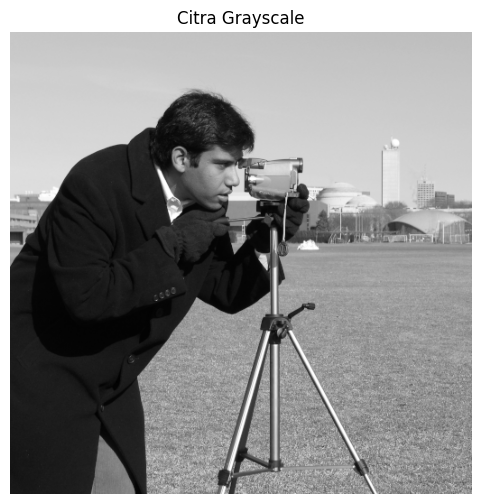

In [3]:
plt.figure(figsize=(8, 6))
plt.imshow(image, cmap="gray")
plt.title("Citra Grayscale")
plt.axis("off")
plt.show()

## Praktikum 1 — Melihat Nilai Piksel

Ambil beberapa nilai piksel dari citra dari variable `image` yang telah di inisiasi sebelumnya dengan gambar ***camera***



In [4]:
# Membuat daftar koordinat piksel yang akan diperiksa
# Setiap pasangan berisi (baris, kolom) pada citra
koordinat = [(50, 50), (100, 100), (150, 150), (200, 200)]

# Melakukan perulangan untuk mengambil setiap koordinat
for r, c in koordinat:

    # Mengakses nilai piksel berdasarkan koordinat baris (r) dan kolom (c)
    # Kemudian menampilkan koordinat beserta nilai pikselnya
    print(f"Piksel [{r}, {c}] = {image[r, c]}")

Piksel [50, 50] = 207
Piksel [100, 100] = 212
Piksel [150, 150] = 36
Piksel [200, 200] = 47


Penjelasan konsep:
- `koordinat`: Menyimpan daftar posisi piksel yang ingin diperiksa.
- `for r, c in koordinat`: Mengambil setiap pasangan koordinat, dengan r sebagai indeks baris (row) dan c sebagai indeks kolom (column).
- `image[r, c]`: Mengakses nilai intensitas piksel pada posisi tersebut.
- `print()`: Menampilkan posisi dan nilai piksel ke layar.

Indeks diatas digunakan jika citra berukuran 256 × 256 piksel, seluruh koordinat di atas masih valid karena indeks dimulai dari 0.

Untuk citra grayscale, hasil image[r, c] berupa satu nilai intensitas (0–255). Sementara pada citra RGB, hasilnya berupa tiga nilai kanal warna, yaitu [R, G, B].

![link alt](https://knowthecode.io/wp-content/uploads/2016/10/cs0100-2.13pgrid.jpg)

### Pertanyaan Praktikum 1

1. Apakah nilai setiap piksel sama?
2. Apa arti nilai piksel yang mendekati `0`?
3. Apa arti nilai piksel yang mendekati `255`?



### **Jawaban Pertanyaan Praktikum 1**
#
#
#




---



# BAGIAN 2 — Operasi Piksel dan Brightness

## 2.1 Brightness
### 2.1.1 Konsep Brightness
**Brightness (kecerahan)** merupakan proses pengolahan citra yang bertujuan untuk membuat gambar menjadi lebih terang atau lebih gelap dengan mengubah nilai intensitas piksel.

Rumus sederhana:

\\[ I\_{baru}(x,y) = I\_{lama}(x,y) + B \\]

Keterangan:

- \\(I\_{baru}\\) = nilai intensitas piksel setelah perubahan.
- \\(I\_{lama}\\) = nilai intensitas piksel asli.
- \\(B\\) = nilai perubahan brightness.

Pengaruh nilai brightness:

| Nilai Brightness | Pengaruh           |
| ---------------- | ------------------ |
| +50              | Citra lebih terang |
| +30              | Citra lebih terang |
| 0                | Citra tetap        |
| -30              | Citra lebih gelap  |
| -50              | Citra lebih gelap  |

**Mengapa perlu clipping (pembatasan/pemotongan)?**

Pada citra grayscale 8-bit, nilai intensitas hanya boleh berada pada rentang 0–255.

- Jika hasil perhitungan lebih dari 255, nilainya dibatasi menjadi 255.
- Jika hasil perhitungan kurang dari 0, nilainya dibatasi menjadi 0.

Secara matematis:

$$I_{baru} = min(255,max(0,I_{lama}+B))$$

### **2.1.2 Visualisasi Perubahan Brightness**

<div style="display: flex; justify-content: center; gap: 20px;">

  <figure style="text-align: center; margin: 0; width:45%;">
    <img src="https://i.sstatic.net/MCZ7o.jpg" alt="Deskripsi 1" width="320">
    <figcaption> <b>Citra asli</b> - Brightness = 0 </figcaption>
  </figure>

  <figure style="text-align: center; margin: 0; width:40%;">
    <img src="https://miro.medium.com/v2/resize:fit:828/format:webp/0*MisK3q_-36cFvpXx" alt="Deskripsi 2" width="320">
    <figcaption><b>Citra lebih terang - </b> Brightness = +50 (ilustrasi)</figcaption>
  </figure>

</div>




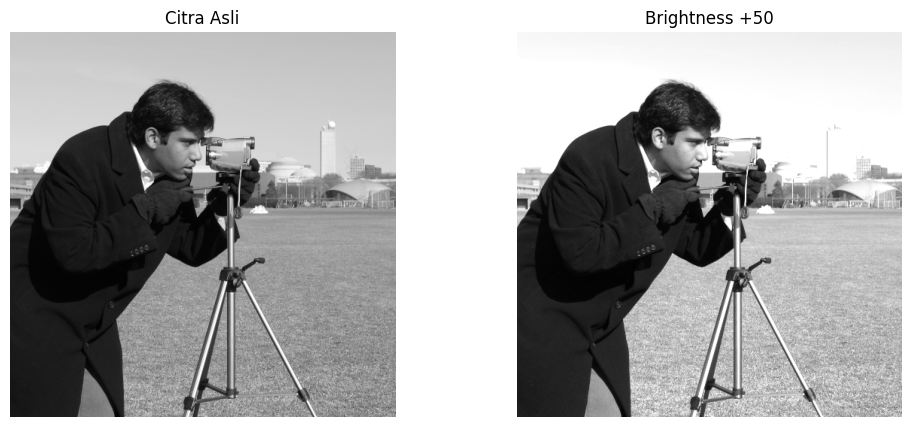

In [5]:
# @title Source Code Brightness Gambar

# Menentukan nilai perubahan kecerahan (brightness)
# Nilai positif membuat citra lebih terang,
# sedangkan nilai negatif membuat citra lebih gelap.
brightness = 50

# Mengubah tipe data citra menjadi int16 agar operasi
# penjumlahan tidak mengalami overflow pada tipe uint8.
bright_image = np.clip(
    image.astype(np.int16) + brightness,  # Menambahkan nilai brightness ke setiap piksel citra asli
    0, # Menentukan batas minimum intensitas piksel, yaitu 0 (hitam)
    255 # Menentukan batas maksimum intensitas piksel, yaitu 255 (putih)
).astype(np.uint8) # Mengubah kembali hasil pengolahan menjadi uint8 (8-bit)
                    # karena citra grayscale umumnya menggunakan rentang 0-255.

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(bright_image, cmap="gray")
plt.title(f"Brightness {brightness:+d}")
plt.axis("off")

plt.show()

### Mengapa menggunakan code `np.clip()`?

Misalnya:

```text
230 + 50 = 280
```

Padahal nilai maksimum citra 8-bit adalah `255`.

`np.clip()` akan membatasi:

```text
280 → 255
```

Begitu juga jika hasil negatif:

```text
-20 → 0
```

## Praktikum 2 — Eksperimen Brightness

1. Coba nilai berikut secara bergantian kemudian amati perubahan dari citra
   * `-50`
   * `0`
   * `20`
   * `50`
   * `100`

2. Apa yang terjadi jika nilai brightness semakin besar?
3. Apa yang terjadi jika nilai brightness negatif?
4. Mengapa kita menggunakan `np.clip()`?
5. Apa yang terjadi jika `np.clip()` tidak digunakan?

### **Jawaban Pertanyaan Praktikum 2 - Eksperimen Brightness**
#
#
#




---



# BAGIAN 3 — Contrast

## 3.1 Apa itu Contrast?

**Contrast (kontras)** menunjukkan tingkat perbedaan intensitas antara area gelap dan area terang pada sebuah citra.

Kontras menentukan seberapa jelas perbedaan antara objek dan latar belakang.

- **Kontras rendah:** Perbedaan area gelap dan terang relatif kecil sehingga gambar terlihat pucat atau kurang jelas.
- **Kontras tinggi:** Perbedaan area gelap dan terang lebih besar sehingga detail objek terlihat lebih tegas.

### **3.1.1. Ilustrasi Perbedaan Kontras**

**Kontras rendah** (Perbedaan intensitas piksel relatif kecil.)<br>
![Yuriko Noguchi (@Nogu_writer7) on X](https://pbs.twimg.com/profile_images/1876500872064270337/Pq1ZakBV.jpg)

**Kontras tinggi** Perbedaan intensitas piksel lebih tegas.
![Post in Miles Davis su © Jazzinphoto | Miles davis, Irving penn, Irving penn portrait](https://i.pinimg.com/736x/f1/73/18/f17318342deff0a9054acec754864647.jpg)



### **3.2. Perbedaan Nilai Intensitas**

Contoh sederhana:

```
Kontras rendah:
100  110  120  130  140

Kontras lebih tinggi:
20   60   120  180  240
```

Pada contoh tersebut, nilai intensitas pertama berada pada rentang yang sempit, sedangkan contoh kedua memiliki rentang nilai yang lebih lebar.

Artinya, semakin besar penyebaran nilai intensitas, semakin besar pula potensi kontras citra.

### **3.3. Rumus Perubahan Contrast**

Salah satu operasi sederhana untuk mengubah kontras adalah:

$$
I_{baru}(x,y)=I_{lama}(x,y)\times C
$$


Keterangan:

- \\[(I_{baru})\\ = nilai intensitas piksel setelah perubahan.
- \\(I\_{lama}\\) = nilai intensitas piksel asli.
- \\(C\\) = faktor pengali kontras (*contrast factor*).

Pengaruh nilai contrast:

| Faktor Kontras | Pengaruh                      |
| -------------- | ----------------------------- |
| 0.5            | Kontras cenderung menurun     |
| 0.8            | Kontras sedikit menurun       |
| 1.0            | Tidak ada perubahan           |
| 1.5            | Kontras meningkat             |
| 2.0            | Kontras meningkat lebih besar |

**Catatan:** Pengalian langsung terhadap intensitas piksel akan mengubah tingkat kecerahan sekaligus kontras. Untuk pengaturan kontras yang lebih terkontrol, biasanya digunakan nilai titik tengah (128) sebagai acuan.

Rumus alternatif:
$$I_{baru}(x,y)=I_{lama}(x,y)\times C$$


### **3.4. Implementasi Python**

Berikut contoh penerapan perubahan kontras menggunakan NumPy.

```
# Menentukan faktor kontrascontrast = 1.5# Mengubah kontras citra berdasarkan titik tengah 128contrast_image = np.clip(    128 + (image.astype(np.float32) - 128) * contrast,    0,    255).astype(np.uint8)
```

Penjelasan:

- `contrast = 1.5`: Menentukan faktor peningkatan kontras.
- `image.astype(np.float32)`: Mengubah tipe data agar perhitungan desimal dapat dilakukan.
- `image - 128`: Menghitung selisih intensitas terhadap titik tengah.
- `* contrast`: Mengalikan selisih intensitas dengan faktor kontras.
- `+ 128`: Mengembalikan titik acuan intensitas.
- `np.clip()`: Membatasi nilai piksel pada rentang 0–255.
- `astype(np.uint8)`: Mengubah kembali hasil menjadi tipe data citra 8-bit.

### **3.5. Eksperimen Perubahan Contrast**

Judul kode: **Eksperimen Perubahan Contrast dengan Berbagai Faktor Pengali**

```
# Menentukan beberapa variasi faktor kontrascontrast_values = [0.5, 0.8, 1.0, 1.5, 2.0]# Melakukan pengujian pada setiap nilai kontrasfor c in contrast_values:    # Mengubah kontras berdasarkan titik tengah 128    result = np.clip(        128 + (image.astype(np.float32) - 128) * c,        0,        255    ).astype(np.uint8)
```

**Pertanyaan diskusi untuk mahasiswa:**

1. Apa perbedaan citra ketika faktor kontras bernilai 0.5 dan 2.0?
2. Mengapa faktor kontras 1.0 tidak mengubah citra?
3. Apa fungsi penggunaan `np.clip()` dalam proses pengolahan kontras?
4. Mengapa titik tengah 128 digunakan sebagai acuan pada rumus alternatif?

**Inti pembelajaran:** Brightness mengatur tingkat kecerahan citra, sedangkan contrast mengatur perbedaan intensitas antara area gelap dan terang. Keduanya merupakan operasi dasar yang penting dalam pengolahan citra digital.

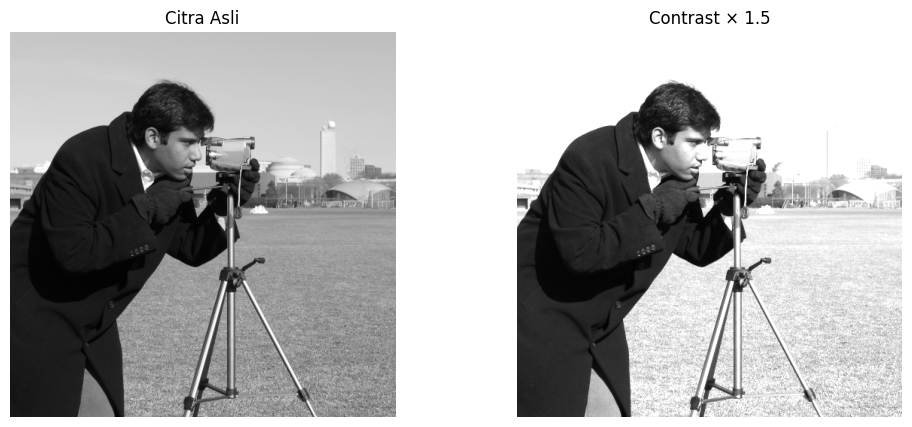

In [7]:
contrast = 1.5

contrast_image = np.clip(
    image.astype(np.float32) * contrast,
    0,
    255
).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(contrast_image, cmap="gray")
plt.title(f"Contrast × {contrast}")
plt.axis("off")

plt.show()

## 🧪 Praktikum 3 — Eksperimen Contrast

Uji:

- `0.5`
- `1.0`
- `1.5`
- `2.0`

Amati perubahan visual.

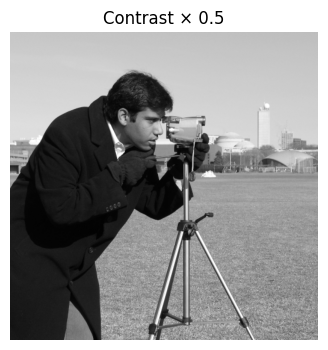

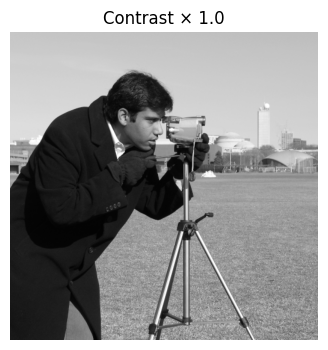

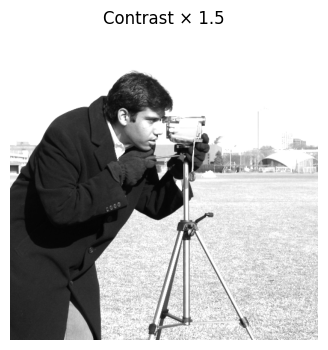

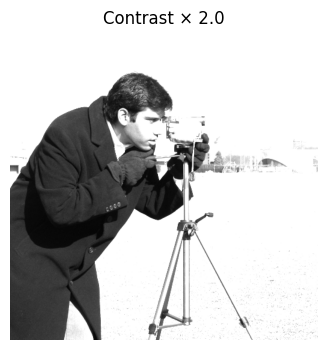

In [8]:
contrast_values = [0.5, 1.0, 1.5, 2.0]

for c in contrast_values:
    result = np.clip(
        image.astype(np.float32) * c,
        0,
        255
    ).astype(np.uint8)

    plt.figure(figsize=(4, 4))
    plt.imshow(result, cmap="gray")
    plt.title(f"Contrast × {c}")
    plt.axis("off")
    plt.show()

### ✍️ Analisis Praktikum 3

1. Apa yang terjadi ketika faktor kontras `< 1`?
2. Apa yang terjadi ketika faktor kontras `> 1`?
3. Apakah faktor kontras yang lebih besar selalu menghasilkan citra yang lebih baik?

**Jawaban mahasiswa:**

# BAGIAN 4 — Kombinasi Brightness dan Contrast

Brightness dan contrast dapat diterapkan bersama.

Secara sederhana:

```text
piksel baru = piksel lama × contrast + brightness
```

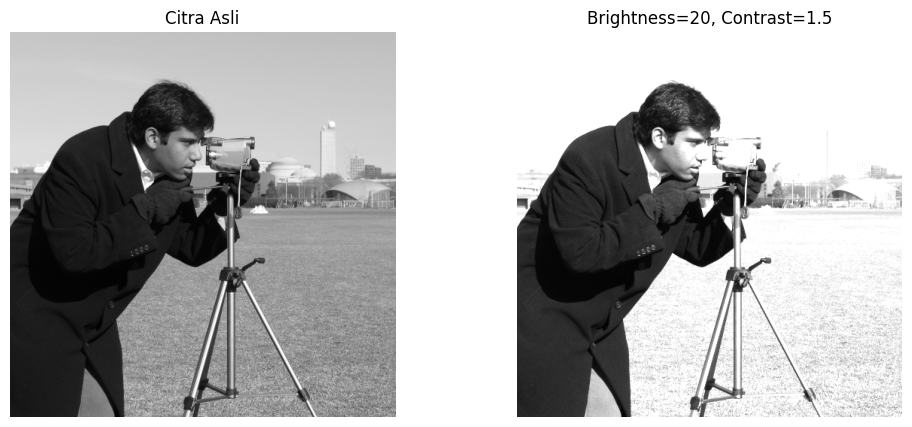

In [9]:
brightness = 20
contrast = 1.5

adjusted_image = np.clip(
    image.astype(np.float32) * contrast + brightness,
    0,
    255
).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(adjusted_image, cmap="gray")
plt.title(f"Brightness={brightness}, Contrast={contrast}")
plt.axis("off")

plt.show()

## 🧪 Praktikum 4 — Mencari Kombinasi Parameter

Coba minimal 3 kombinasi berikut:

1. `brightness = -30`, `contrast = 1.5`
2. `brightness = 30`, `contrast = 2.0`
3. `brightness = 0`, `contrast = 0.5`

Kemudian tentukan kombinasi yang menurut Anda paling baik.

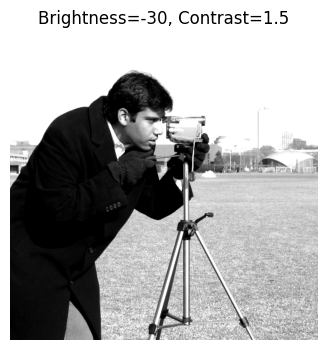

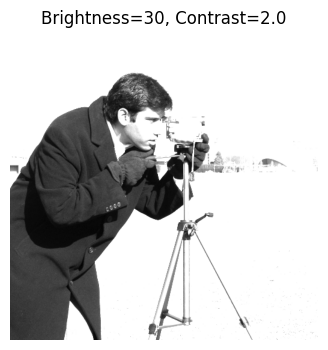

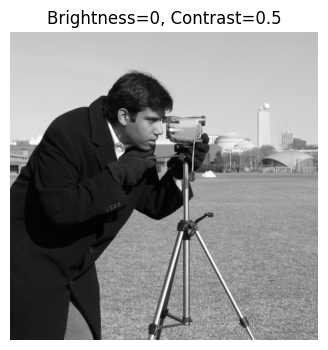

In [10]:
kombinasi = [
    (-30, 1.5),
    (30, 2.0),
    (0, 0.5)
]

for b, c in kombinasi:
    result = np.clip(
        image.astype(np.float32) * c + b,
        0,
        255
    ).astype(np.uint8)

    plt.figure(figsize=(4, 4))
    plt.imshow(result, cmap="gray")
    plt.title(f"Brightness={b}, Contrast={c}")
    plt.axis("off")
    plt.show()

### ✍️ Jawaban

Kombinasi terbaik menurut saya:

**Brightness:**  
**Contrast:**  

**Alasan:**

# BAGIAN 5 — Histogram

## 5.1 Apa itu Histogram?

Histogram menunjukkan distribusi jumlah piksel berdasarkan nilai intensitas.

```text
0 ---------------------------- 255
gelap                         terang
```

- Histogram banyak di kiri → citra cenderung gelap.
- Histogram banyak di kanan → citra cenderung terang.
- Histogram tersebar lebar → rentang intensitas lebih luas.
- Histogram terkonsentrasi pada rentang sempit → salah satu indikasi kontras rendah.

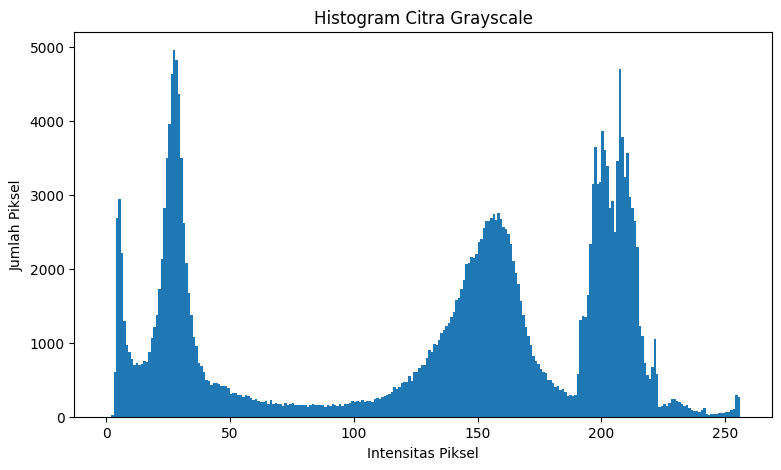

In [11]:
plt.figure(figsize=(9, 5))
plt.hist(image.ravel(), bins=256, range=(0, 256))
plt.title("Histogram Citra Grayscale")
plt.xlabel("Intensitas Piksel")
plt.ylabel("Jumlah Piksel")
plt.show()

### Apa fungsi `ravel()`?

Citra berbentuk array 2 dimensi:

```text
tinggi × lebar
```

`ravel()` mengubahnya menjadi satu dimensi sehingga seluruh nilai piksel dapat dianalisis sebagai kumpulan data.

## 🧪 Praktikum 5 — Citra dan Histogram

Bandingkan citra asli dengan histogramnya.

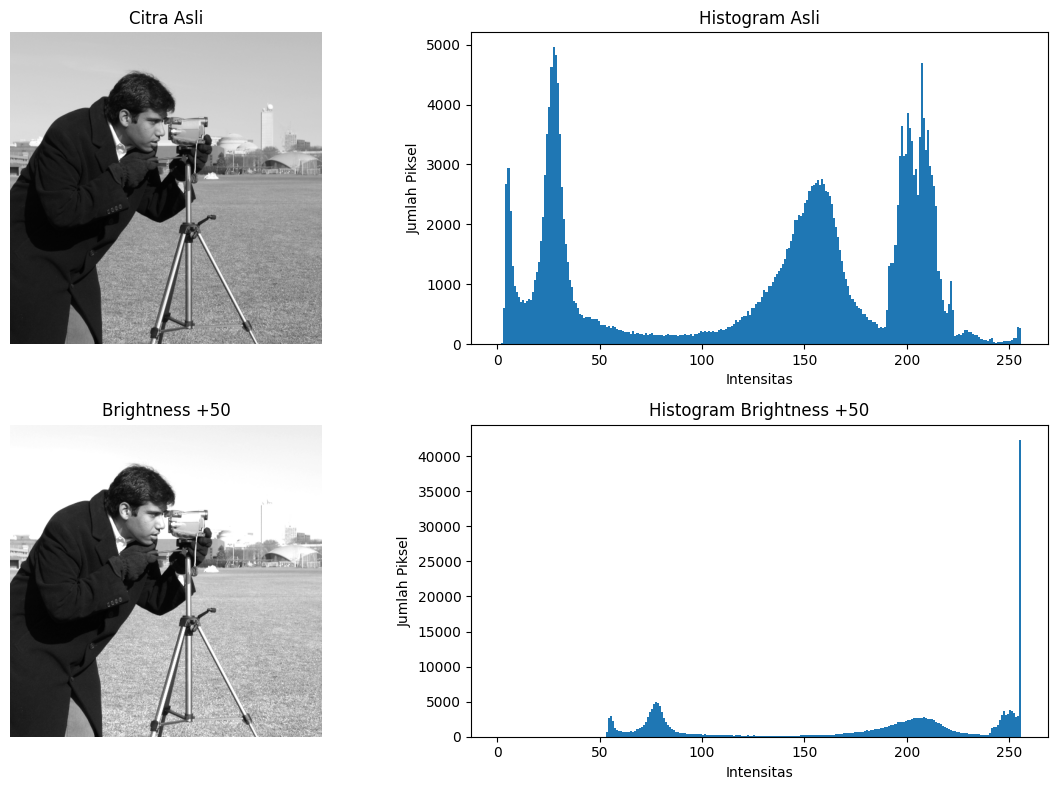

In [12]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.hist(image.ravel(), bins=256, range=(0, 256))
plt.title("Histogram Asli")
plt.xlabel("Intensitas")
plt.ylabel("Jumlah Piksel")

plt.subplot(2, 2, 3)
plt.imshow(bright_image, cmap="gray")
plt.title("Brightness +50")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.hist(bright_image.ravel(), bins=256, range=(0, 256))
plt.title("Histogram Brightness +50")
plt.xlabel("Intensitas")
plt.ylabel("Jumlah Piksel")

plt.tight_layout()
plt.show()

### ✍️ Analisis Praktikum 5

1. Apakah histogram berubah setelah brightness ditingkatkan?
2. Ke arah mana distribusi histogram cenderung bergeser?
3. Apakah perubahan histogram sesuai dengan perubahan visual citra?

**Jawaban mahasiswa:**

# BAGIAN 6 — Histogram dengan `skimage.exposure`

Scikit-Image menyediakan fungsi `exposure.histogram()` untuk memperoleh histogram citra.

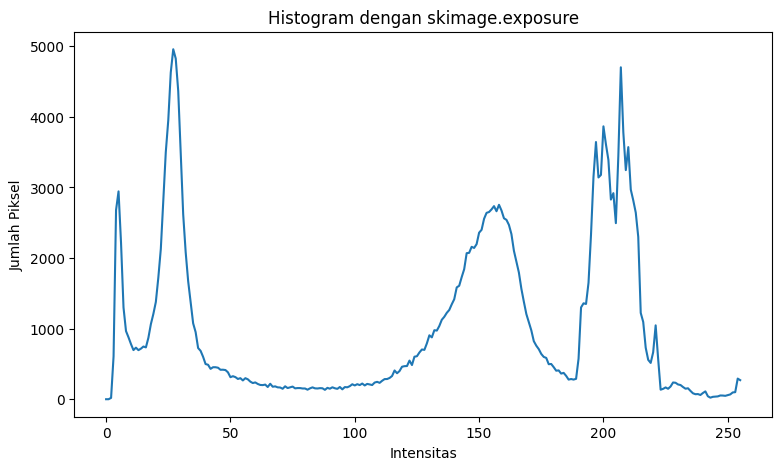

In [13]:
hist, bins = exposure.histogram(image)

plt.figure(figsize=(9, 5))
plt.plot(bins, hist)
plt.title("Histogram dengan skimage.exposure")
plt.xlabel("Intensitas")
plt.ylabel("Jumlah Piksel")
plt.show()

## 🧪 Praktikum 6 — Membandingkan Histogram

Bandingkan histogram citra asli dan citra yang kontrasnya ditingkatkan.

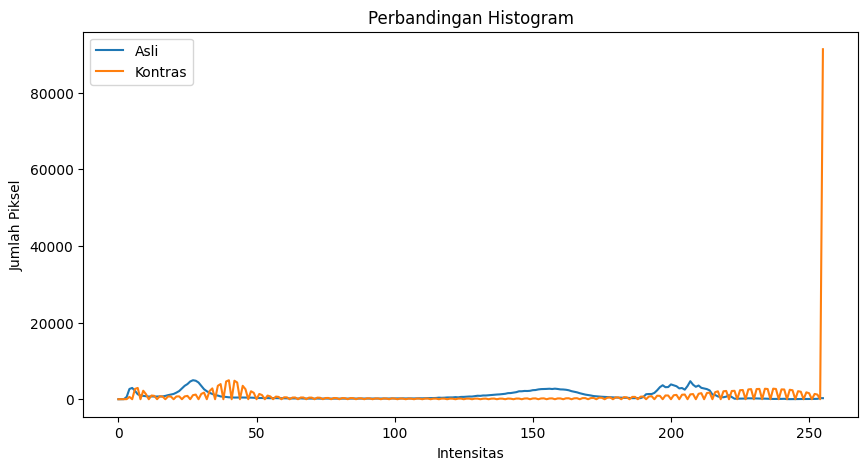

In [14]:
hist_original, bins_original = exposure.histogram(image)
hist_contrast, bins_contrast = exposure.histogram(contrast_image)

plt.figure(figsize=(10, 5))

plt.plot(bins_original, hist_original, label="Asli")
plt.plot(bins_contrast, hist_contrast, label="Kontras")

plt.xlabel("Intensitas")
plt.ylabel("Jumlah Piksel")
plt.title("Perbandingan Histogram")
plt.legend()
plt.show()

### ✍️ Pertanyaan

Apa perbedaan histogram citra asli dengan citra yang kontrasnya ditingkatkan?

**Jawaban mahasiswa:**

# BAGIAN 7 — Contrast Stretching

## 7.1 Konsep

Misalnya citra hanya menggunakan rentang:

```text
50 ---------------- 180
```

Padahal rentang grayscale tersedia:

```text
0 ------------------------------ 255
```

Contrast stretching memetakan rentang intensitas agar lebih optimal.

```text
Sebelum:
50 ---------------- 180

Sesudah:
0 ------------------------------ 255
```

Tujuannya adalah meningkatkan pemisahan antara bagian gelap dan terang.

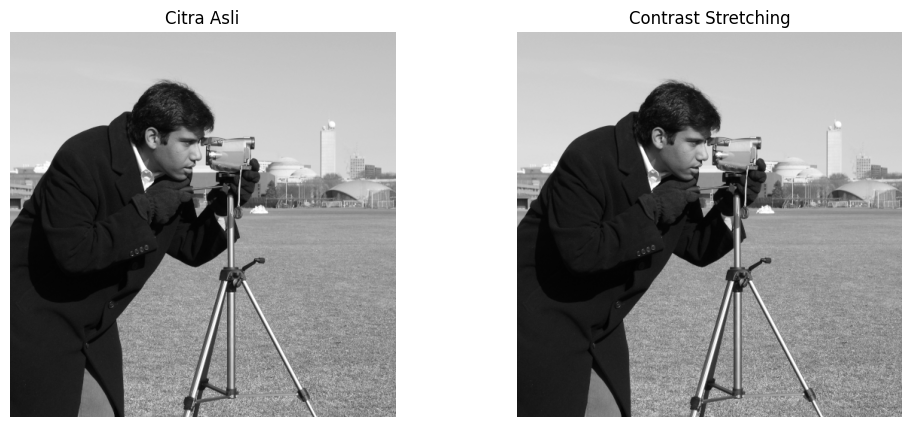

In [15]:
stretched = exposure.rescale_intensity(
    image,
    in_range="image",
    out_range=(0, 255)
).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(stretched, cmap="gray")
plt.title("Contrast Stretching")
plt.axis("off")

plt.show()

## 🧪 Praktikum 7 — Membandingkan Histogram

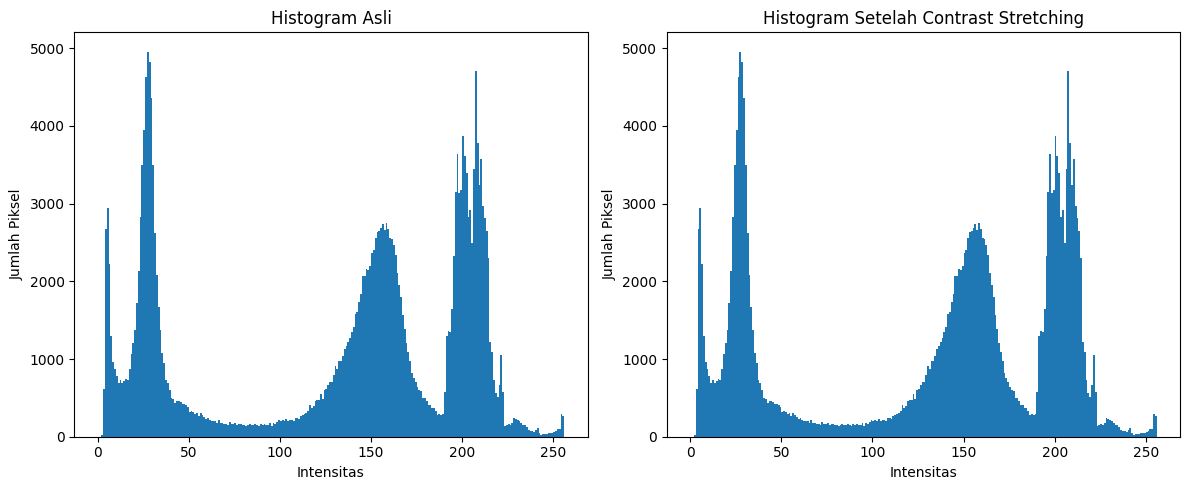

In [16]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(image.ravel(), bins=256, range=(0, 256))
plt.title("Histogram Asli")
plt.xlabel("Intensitas")
plt.ylabel("Jumlah Piksel")

plt.subplot(1, 2, 2)
plt.hist(stretched.ravel(), bins=256, range=(0, 256))
plt.title("Histogram Setelah Contrast Stretching")
plt.xlabel("Intensitas")
plt.ylabel("Jumlah Piksel")

plt.tight_layout()
plt.show()

### 🔎 Analisis

Perhatikan apakah rentang intensitas menjadi lebih luas dan bagaimana perubahan tersebut memengaruhi tampilan citra.

**Jawaban mahasiswa:**

# BAGIAN 8 — Studi Kasus: Citra dengan Kontras Rendah

## 🎯 Skenario

Sebuah sistem komputer harus mengenali objek dari citra grayscale.

Kondisinya:
- resolusi citra rendah;
- objek hampir sama dengan background;
- pencahayaan kurang baik;
- batas objek kurang jelas.

Preprocessing dapat digunakan sebelum segmentasi atau pengenalan objek.

```text
Citra
  ↓
Analisis histogram
  ↓
Kontras rendah
  ↓
Contrast stretching
  ↓
Objek lebih mudah dibedakan
  ↓
Segmentasi / pengenalan objek
```

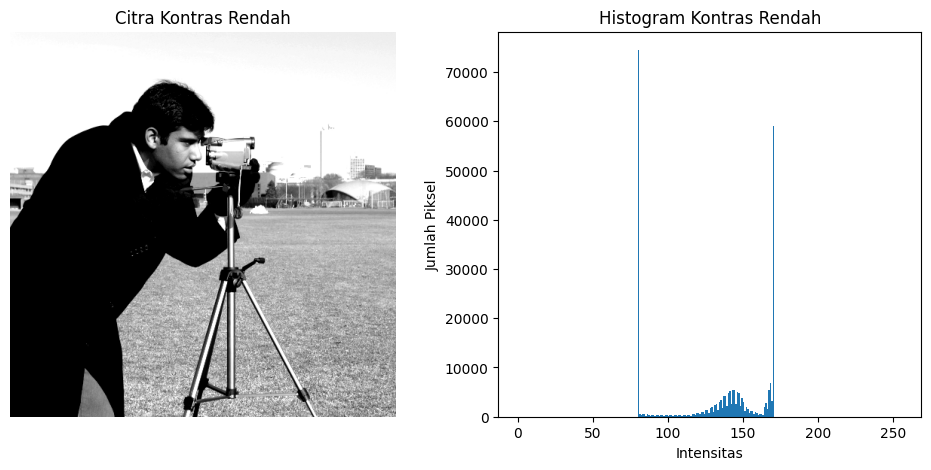

In [17]:
low_contrast = exposure.rescale_intensity(
    image,
    in_range=(50, 200),
    out_range=(80, 170)
).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(low_contrast, cmap="gray")
plt.title("Citra Kontras Rendah")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.hist(low_contrast.ravel(), bins=256, range=(0, 256))
plt.title("Histogram Kontras Rendah")
plt.xlabel("Intensitas")
plt.ylabel("Jumlah Piksel")

plt.show()

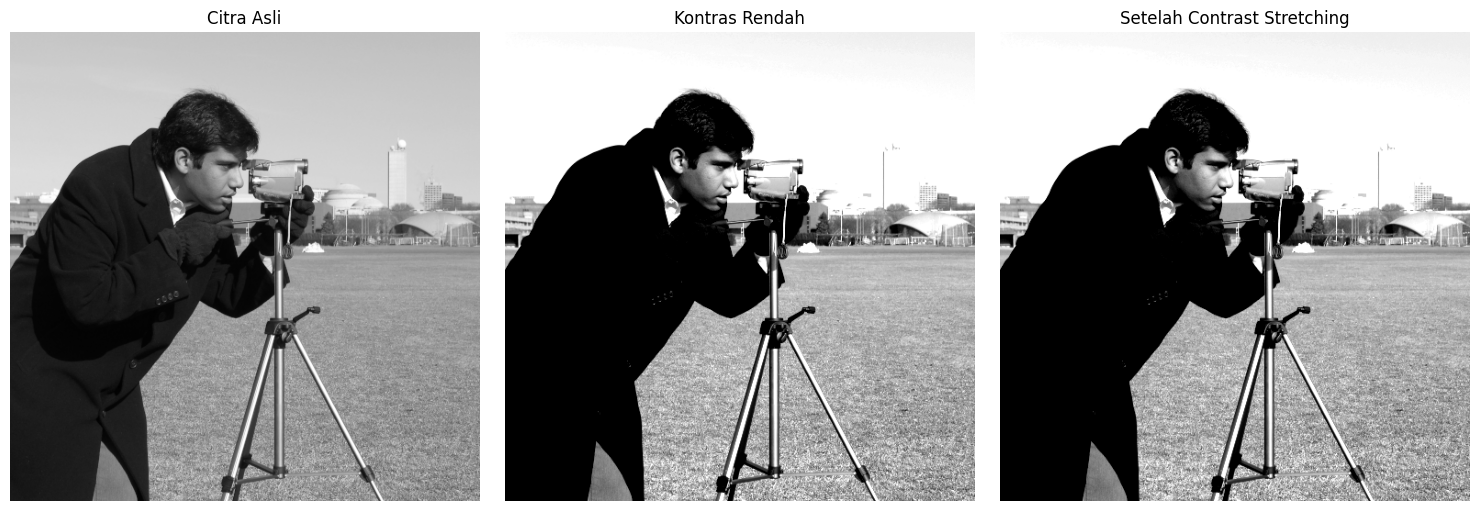

In [18]:
improved = exposure.rescale_intensity(
    low_contrast,
    in_range="image",
    out_range=(0, 255)
).astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(low_contrast, cmap="gray")
plt.title("Kontras Rendah")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(improved, cmap="gray")
plt.title("Setelah Contrast Stretching")
plt.axis("off")

plt.tight_layout()
plt.show()

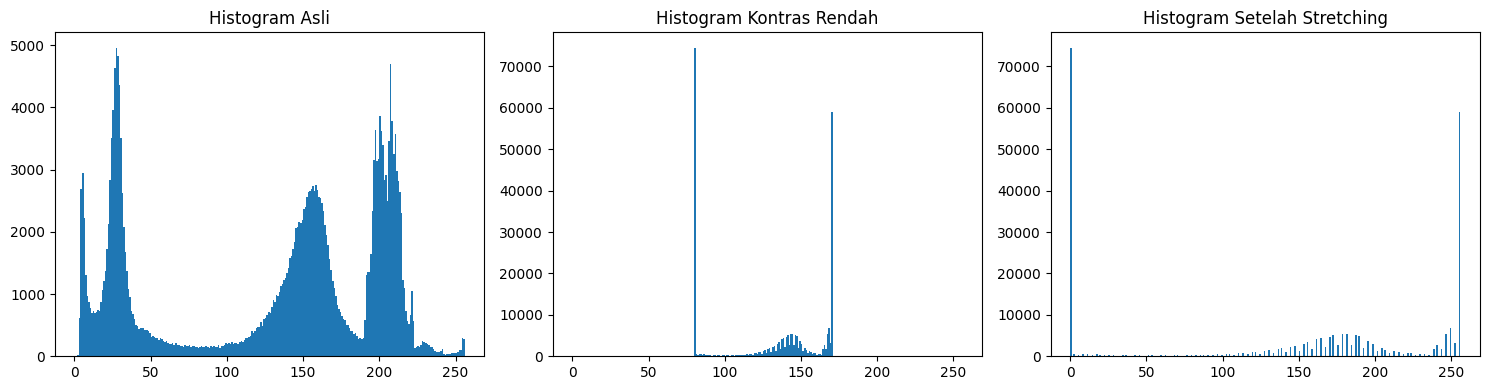

In [19]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(image.ravel(), bins=256, range=(0, 256))
plt.title("Histogram Asli")

plt.subplot(1, 3, 2)
plt.hist(low_contrast.ravel(), bins=256, range=(0, 256))
plt.title("Histogram Kontras Rendah")

plt.subplot(1, 3, 3)
plt.hist(improved.ravel(), bins=256, range=(0, 256))
plt.title("Histogram Setelah Stretching")

plt.tight_layout()
plt.show()

### 🧠 Pertanyaan Analisis Studi Kasus

1. Mengapa citra dengan kontras rendah dapat menyulitkan sistem pengenalan objek?
2. Apa yang terjadi terhadap distribusi histogram setelah contrast stretching?
3. Apa perbedaan visual citra asli, kontras rendah, dan hasil stretching?
4. Mengapa peningkatan kontras dapat membantu segmentasi?
5. Apakah contrast stretching selalu menghasilkan citra yang lebih baik? Jelaskan.

**Jawaban mahasiswa:**

# BAGIAN 9 — Membuat Fungsi Sendiri

## 🧪 Praktikum 8 — Fungsi Brightness

Lengkapi fungsi berikut.

In [20]:
def ubah_brightness(image, nilai):
    hasil = np.clip(
        image.astype(np.int16) + nilai,
        0,
        255
    ).astype(np.uint8)

    return hasil

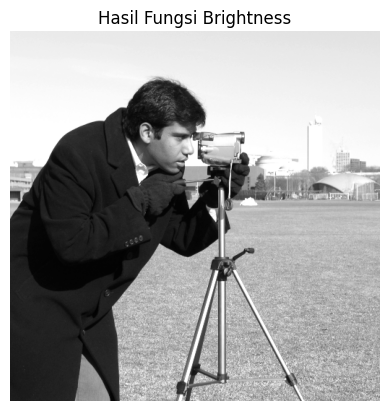

In [21]:
hasil_brightness = ubah_brightness(image, 40)

plt.imshow(hasil_brightness, cmap="gray")
plt.title("Hasil Fungsi Brightness")
plt.axis("off")
plt.show()

## 🧪 Praktikum 9 — Fungsi Contrast

In [22]:
def ubah_contrast(image, faktor):
    hasil = np.clip(
        image.astype(np.float32) * faktor,
        0,
        255
    ).astype(np.uint8)

    return hasil

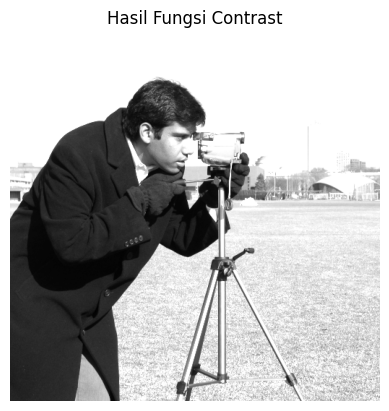

In [23]:
hasil_contrast = ubah_contrast(image, 1.5)

plt.imshow(hasil_contrast, cmap="gray")
plt.title("Hasil Fungsi Contrast")
plt.axis("off")
plt.show()

# BAGIAN 10 — Eksperimen Parameter

Sekarang lakukan eksplorasi parameter secara sistematis.

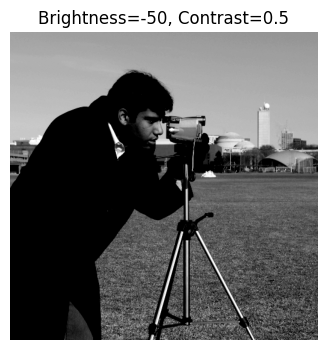

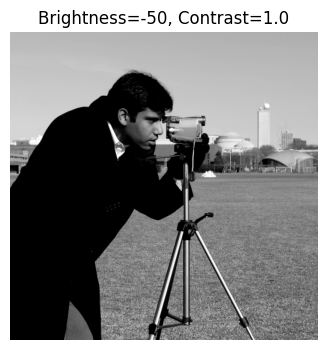

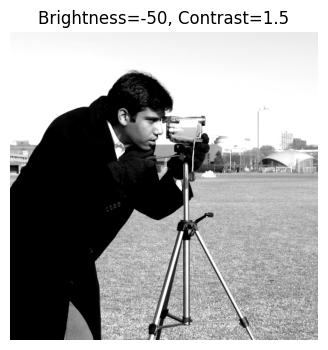

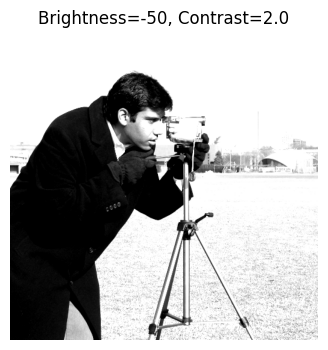

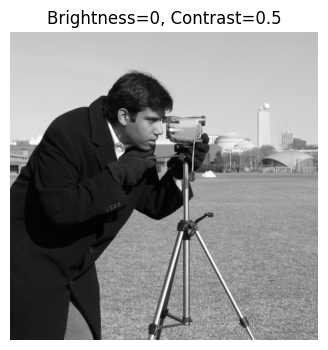

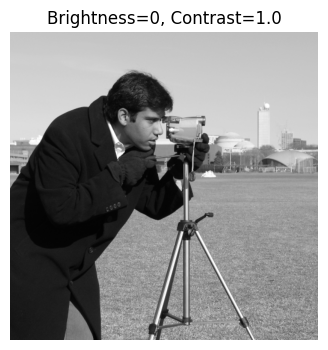

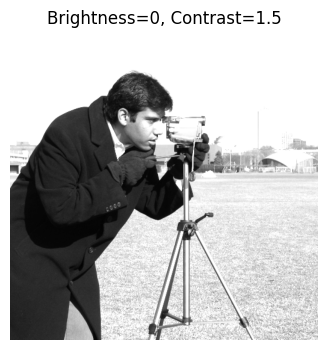

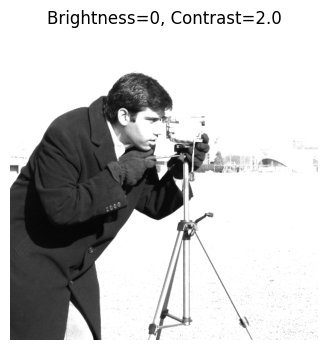

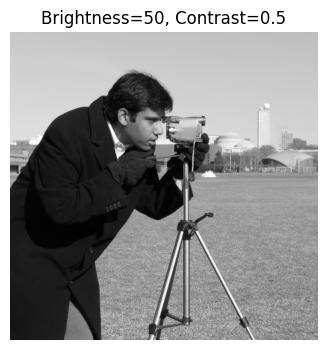

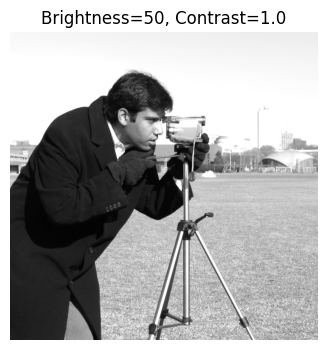

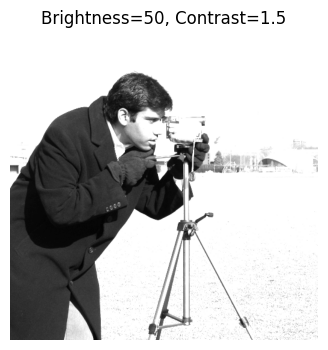

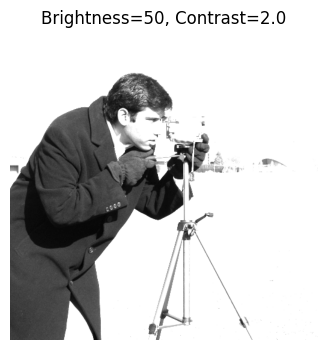

In [24]:
brightness_values = [-50, 0, 50]
contrast_values = [0.5, 1.0, 1.5, 2.0]

for brightness in brightness_values:
    for contrast in contrast_values:

        hasil = np.clip(
            image.astype(np.float32) * contrast + brightness,
            0,
            255
        ).astype(np.uint8)

        plt.figure(figsize=(4, 4))
        plt.imshow(hasil, cmap="gray")
        plt.title(
            f"Brightness={brightness}, Contrast={contrast}"
        )
        plt.axis("off")
        plt.show()

### 🎯 Tantangan

Tentukan kombinasi **brightness** dan **contrast** yang menurut Anda menghasilkan citra paling mudah dikenali.

**Brightness =**

**Contrast =**

**Alasan:**

# BAGIAN 11 — MINI PROJECT

## 🎯 Peningkatan Kualitas Citra

### Skenario

Anda bertindak sebagai **image processing engineer**.

Diberikan satu citra grayscale yang memiliki kualitas visual kurang baik. Tugas Anda adalah melakukan preprocessing sebelum citra digunakan untuk proses pengenalan objek.

### Tahapan

```text
Citra
  ↓
Analisis piksel
  ↓
Histogram
  ↓
Brightness
  ↓
Contrast
  ↓
Contrast Stretching
  ↓
Perbandingan hasil
  ↓
Kesimpulan
```

## Tahap 1 — Upload Citra

Upload satu citra grayscale milik sendiri.

**Saran:** gunakan citra dengan objek yang cukup jelas sehingga perubahan kontras dapat diamati.

In [25]:
from google.colab import files

uploaded = files.upload()
filename = list(uploaded.keys())[0]

image_project = io.imread(filename, as_gray=True)

print("Nama file :", filename)
print("Ukuran    :", image_project.shape)
print("Tipe data :", image_project.dtype)
print("Minimum   :", image_project.min())
print("Maksimum  :", image_project.max())
print("Rata-rata :", image_project.mean())

plt.figure(figsize=(7, 5))
plt.imshow(image_project, cmap="gray")
plt.title("Citra Project")
plt.axis("off")
plt.show()

IndexError: list index out of range

## Tahap 2 — Analisis Histogram

In [ ]:
plt.figure(figsize=(9, 5))
plt.hist(image_project.ravel(), bins=256)
plt.title("Histogram Citra Project")
plt.xlabel("Intensitas")
plt.ylabel("Jumlah Piksel")
plt.show()

## Tahap 3 — Brightness

Sesuaikan nilai brightness dengan kondisi citra.

Karena citra dari `skimage` dapat menggunakan rentang `0–1`, kita gunakan skala tersebut.

In [ ]:
brightness = 0.05

bright_project = np.clip(
    image_project + brightness,
    0,
    1
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_project, cmap="gray")
plt.title("Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(bright_project, cmap="gray")
plt.title(f"Brightness +{brightness}")
plt.axis("off")

plt.show()

## 🧪 Eksperimen

Coba ubah:

```python
brightness = -0.05
brightness = 0.05
brightness = 0.10
```

Pilih hasil yang paling sesuai.

## Tahap 4 — Contrast

In [ ]:
contrast = 1.5

contrast_project = np.clip(
    bright_project * contrast,
    0,
    1
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(bright_project, cmap="gray")
plt.title("Setelah Brightness")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(contrast_project, cmap="gray")
plt.title(f"Contrast × {contrast}")
plt.axis("off")

plt.show()

## Tahap 5 — Contrast Stretching

In [ ]:
stretched_project = exposure.rescale_intensity(
    image_project,
    in_range="image",
    out_range=(0, 1)
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_project, cmap="gray")
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(stretched_project, cmap="gray")
plt.title("Contrast Stretching")
plt.axis("off")

plt.show()

## Tahap 6 — Perbandingan Semua Metode

In [ ]:
plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(image_project, cmap="gray")
plt.title("Asli")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(bright_project, cmap="gray")
plt.title("Brightness")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(contrast_project, cmap="gray")
plt.title("Brightness + Contrast")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(stretched_project, cmap="gray")
plt.title("Contrast Stretching")
plt.axis("off")

plt.tight_layout()
plt.show()

## Tahap 7 — Perbandingan Histogram

In [ ]:
plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.hist(image_project.ravel(), bins=256)
plt.title("Histogram Asli")

plt.subplot(1, 4, 2)
plt.hist(bright_project.ravel(), bins=256)
plt.title("Histogram Brightness")

plt.subplot(1, 4, 3)
plt.hist(contrast_project.ravel(), bins=256)
plt.title("Histogram Brightness + Contrast")

plt.subplot(1, 4, 4)
plt.hist(stretched_project.ravel(), bins=256)
plt.title("Histogram Stretching")

plt.tight_layout()
plt.show()

# 📝 Lembar Analisis Mini Project

### 1. Kondisi Citra Asli
Jelaskan kondisi citra sebelum preprocessing.

**Jawaban:**

---

### 2. Histogram Citra Asli
Bagaimana distribusi intensitas pada citra?

**Jawaban:**

---

### 3. Brightness
Apa perubahan yang terjadi setelah brightness diterapkan?

**Jawaban:**

---

### 4. Contrast
Apa perubahan yang terjadi setelah contrast diterapkan?

**Jawaban:**

---

### 5. Contrast Stretching
Apa perubahan visual dan histogram setelah contrast stretching?

**Jawaban:**

---

### 6. Metode Terbaik
Metode mana yang paling baik untuk citra Anda?

**Jawaban:**

---

### 7. Alasan
Jelaskan alasan berdasarkan citra dan histogram.

**Jawaban:**

# 🧩 BAGIAN 12 — Kuis Pemahaman

## Soal 1
Jika nilai piksel adalah `50` dan brightness ditambah `30`, berapa nilai baru?

**Jawaban:** 80

## Soal 2
Apa yang terjadi jika brightness dikurangi?

**Jawaban:** Citra menjadi lebih gelap.

## Soal 3
Apa fungsi histogram?

**Jawaban:** Melihat distribusi jumlah piksel berdasarkan nilai intensitas.

## Soal 4
Apa indikasi histogram terkonsentrasi pada rentang yang sempit?

**Jawaban:** Salah satu indikasinya adalah citra memiliki kontras yang rendah.

## Soal 5
Apa tujuan `rescale_intensity()`?

**Jawaban:** Memetakan atau menyesuaikan rentang intensitas citra agar penggunaan rentang intensitas menjadi lebih optimal.

# 📚 Kesimpulan

Pada pertemuan ini telah dipelajari:

- **Piksel** → elemen dasar penyusun citra.
- **Brightness** → mengatur tingkat kecerahan.
- **Contrast** → mengatur perbedaan intensitas.
- **Histogram** → melihat distribusi intensitas.
- **Contrast stretching** → memperluas/menyesuaikan rentang intensitas.

Alur penting:

```text
Citra
  ↓
Analisis Piksel
  ↓
Histogram
  ↓
Brightness / Contrast
  ↓
Contrast Stretching
  ↓
Citra Lebih Mudah Dianalisis
  ↓
Segmentasi / Pengenalan Objek
```

> **Inti:** peningkatan kualitas citra merupakan bagian penting dari preprocessing. Citra yang lebih baik secara visual dan distribusi intensitas dapat membantu tahap pengolahan berikutnya, seperti segmentasi dan pengenalan objek.

# 📌 TUGAS PRAKTIKUM PERTEMUAN 6

## Tugas 1 — Operasi Piksel
Buat program untuk:
- menampilkan nilai piksel;
- mengubah brightness;
- mengubah contrast.

## Tugas 2 — Histogram
Tampilkan:
- citra asli;
- histogram citra asli;
- citra setelah brightness;
- histogram setelah brightness.

## Tugas 3 — Contrast Stretching
Gunakan:

```python
exposure.rescale_intensity()
```

Bandingkan:
- citra sebelum;
- citra sesudah;
- histogram sebelum;
- histogram sesudah.

## Tugas 4 — Mini Project
Gunakan satu citra grayscale milik sendiri dan lakukan:

```text
Analisis citra
      ↓
Histogram
      ↓
Brightness
      ↓
Contrast
      ↓
Contrast Stretching
      ↓
Perbandingan
      ↓
Kesimpulan
```

### Output yang dikumpulkan
1. File Google Colab `.ipynb`.
2. Citra yang digunakan.
3. Hasil setiap tahap preprocessing.
4. Histogram yang diperlukan.
5. Analisis singkat.
6. Kesimpulan metode yang paling sesuai.

**Catatan:** mahasiswa wajib mengubah parameter, mengamati perubahan citra dan histogram, lalu menjelaskan hasilnya.